# Module 5 — Task 2: Stock ranking and portfolio

**Business problem (brief, verbatim):**
> NovaFin manages an equity portfolio. The investment committee wants to know: **Can ML identify stocks with superior future returns?**

**Task 2 (brief, verbatim):**
> **Task 2 — Stock ranking**
> For every rebalance date (assumed):
> 1. Predict future returns
> 2. Rank stocks
> 3. Select top-ranked stocks
> 4. Construct portfolio

**Where this sits:** forecast each stock's next-month return (Task 1) → **rank the stocks, pick the top ones, build a portfolio and check whether it beats simply holding all 15 (this task)** → Module 6 turns ML predictions into optimised portfolios and compares them with equal-weight and Markowitz portfolios.

**Terms used throughout:**
- **Rebalance date:** a day when the portfolio is reset to the chosen stocks. The brief leaves it to us; we use each month-end (decision M5-03). 43 test month-ends, 31 Jan 2023 to 31 Jul 2026; each portfolio is held until the next month-end, so the last one ends on 31 Aug 2026.
- **Equal weight:** every stock held gets the same share of the money (top 5 → 20% each; all 15 → 6.67% each).
- **Annual return:** the yearly growth rate actually achieved, compounded (month after month, gains earn gains).
- **Volatility (annual):** how much the monthly return swings (its standard deviation), scaled to a year by × √12. Higher = a bumpier ride.
- **Excess:** the portfolio's monthly return minus the benchmark's.
- **p:** the chance luck alone gives a result at least this far from zero. **Range 0 to 1;** small (below the line) = probably real, large = probably noise.
- **Turnover:** the share of the portfolio's stocks replaced each month. Each replacement is a sale and a purchase, and both cost money.
- **Maximum drawdown:** the largest fall from a previous high, in %. Shows the worst stretch an investor would have sat through.

| Step | What it does |
| --- | --- |
| 0 | Setup |
| 1 | Task 1's predictions (step 1 of the brief: predict future returns) |
| 2 | Rank the stocks and select the top 5 each month (steps 2–3 of the brief) |
| 3 | Construct the portfolios and the benchmark (step 4 of the brief) |
| 4 | How the portfolios did |
| 5 | Could luck have done as well? Random picks |
| 6 | Check: top 3 and top 7 |
| 7 | Concentration and risk: 5 stocks vs 15 |
| 8 | What it means in ₹ |
| 9 | The portfolio for September 2026: every strategy's picks on the latest rebalance date |
| 10 | Two more checks: quarterly rebalancing, and other ways of weighting the top 5 |
| 11 | Stock by stock: the scorecard |
| 12 | What the results say |
| 13 | Save the outputs |

**Decisions used** (in `docs/decisions.md`): M5-03 monthly rebalancing · M5-04 walk-forward · M5-08 models · M5-10 Task 1 hand-off · M5-05 top 5 · M5-11 benchmark · M5-12 equal weight · M5-13 returns before costs · M5-14 Task 2 output · M5-15 model for Module 6 · M5-17 latest portfolio and extra checks · M5-18 stock scorecard.

## 0. Setup
Works locally and in Google Colab. Takes under a minute. Steps 1–8 read Task 1's predictions; steps 9–10 retrain the models (September 2026 picks, quarterly check).

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # stops a harmless Windows warning when the random forest uses all cores

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_05_equity_markets"
IN_DIR = MODULE_DIR / "outputs" / "task1"          # Task 1's hand-off
OUT_DIR = MODULE_DIR / "outputs" / "task2"
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MODULE_DIR / "helpers"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
import lightgbm as lgb

from m05_data import load_market, month_end_dates, forward_returns, add_features, monthly_panel, INPUTS, ALL_INPUTS
from m05_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA, GAIN, LOSS
apply_style()
plt.close("all")

SEED = 42
TOP_K = 5                      # stocks selected each month (decision M5-05)
K_CHECK = [3, 5, 7]            # the check in step 6 (one table, not a sensitivity study)
N_RANDOM = 1_000               # random-pick portfolios in step 5
START_RUPEES_CRORE = 100       # illustrative portfolio size: ₹100 crore
# The rankers: the past-average benchmark and Task 1's four models. "Predict zero" gives every stock
# the same number, so it cannot rank; the two "all 22 inputs" runs were checks in Task 1 only.
STRATEGIES = ["Past average", "Linear regression", "Ridge regression", "Random forest", "LightGBM"]
LINE = 0.05 / len(STRATEGIES)  # 0.05 = the usual 1-in-20 line, ÷ 5 strategies tested (Bonferroni)
BENCH = "All 15, equal weight"
COLOURS = {"Past average": INK_2, "Linear regression": AQUA, "Ridge regression": BLUE,
           "Random forest": LOSS, "LightGBM": ORANGE, BENCH: INK}
pd.set_option("display.width", 220, "display.max_columns", 30)


def save_table(table: pd.DataFrame, name: str) -> None:
    table.to_csv(OUT_DIR / f"{name}.csv", index=False)


def save_chart(fig, name: str) -> None:
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Reads from:", IN_DIR.relative_to(PROJECT_ROOT).as_posix())
print("Outputs go to:", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())
print(f"Line for 'beats the benchmark': 0.05 ÷ {len(STRATEGIES)} strategies = {LINE:.3f}")

Reads from: module_05_equity_markets/outputs/task1
Outputs go to: module_05_equity_markets/outputs/task2
Line for 'beats the benchmark': 0.05 ÷ 5 strategies = 0.010


## 1. Task 1's predictions (step 1 of the brief: predict future returns)

Task 1 already predicted every stock's next-month return, walk-forward: on each rebalance date every model was trained only on earlier months (decision M5-04). So Task 2 **reads** those predictions instead of retraining.

**What Task 1 found** (decision M5-08): no model's ranking beats luck. The ICs (how well a model orders the 15 stocks each month: −1 backwards, 0 random, +1 perfect; 0.03–0.05 is useful in real markets) are −0.049 to +0.005, and the p-values 0.53–0.93. So this task is the **business check**: would buying each model's top picks have made more money than holding all 15?

In [2]:
pred = pd.read_csv(IN_DIR / "FINAL_M5_T1_return_predictions.csv", parse_dates=["Date"])
pred = pred.sort_values(["Date", "Ticker"]).reset_index(drop=True)
DATES = sorted(pred.Date.unique())

# Each portfolio is bought on a rebalance date and held until the next month-end.
# The last test month-end (31 Jul 2026) is held until 31 Aug 2026, the last month-end in the data.
held_until = dict(zip(DATES, list(DATES[1:]) + [pd.Timestamp("2026-08-31")]))
pred["Held until"] = pred.Date.map(held_until)

print(f"{len(pred):,} rows = {len(DATES)} rebalance dates × {pred.Ticker.nunique()} stocks")
print(f"Rebalance dates: {DATES[0]:%d %b %Y} to {DATES[-1]:%d %b %Y}; last portfolio held until 31 Aug 2026")
print(f"Period invested: {len(DATES)} months = {len(DATES) / 12:.2f} years")
print("Rankers used:", ", ".join(STRATEGIES))
print("Task 1's verdict carried in the file:", pred["Returns predictable"].iloc[0])
display(pred.head(3))

645 rows = 43 rebalance dates × 15 stocks
Rebalance dates: 31 Jan 2023 to 31 Jul 2026; last portfolio held until 31 Aug 2026
Period invested: 43 months = 3.58 years
Rankers used: Past average, Linear regression, Ridge regression, Random forest, LightGBM
Task 1's verdict carried in the file: No: no model beats luck


,Date,Ticker,Sector,Next_Month_Return,Pred: Predict zero,Pred: Past average,Pred: Linear regression,Pred: Ridge regression,Pred: Random forest,Pred: LightGBM,"Pred: Ridge regression, all 22 inputs","Pred: LightGBM, all 22 inputs",Returns predictable,Held until
0,2023-01-31,AXISBANK,Banking,0.039091,0.0,0.007202,-0.037498,-0.033807,-0.016224,-0.014545,-0.019219,0.015620,No: no model beats luck,2023-02-28
1,2023-01-31,BHARTIARTL,Telecom,-0.141212,0.0,0.008297,-0.024830,-0.024183,-0.014816,-0.005037,-0.037884,0.005863,No: no model beats luck,2023-02-28
2,2023-01-31,HDFCBANK,Banking,0.056642,0.0,0.008702,0.001615,0.001834,0.000671,-0.006618,0.005028,0.031189,No: no model beats luck,2023-02-28


## 2. Rank the stocks and select the top 5 each month (steps 2–3 of the brief)

**Rank:** on each rebalance date, order the 15 stocks by predicted next-month return; **rank 1 = highest prediction**. Ties (equal predictions) are broken by ticker name so the result is repeatable.

**Select:** the top 5 (decision M5-05). Why 5:
- it is one-third of the 15 stocks: concentrated enough that a real ranking skill would show up in the return;
- diversified enough not to rest on one or two stocks;
- it was the planning proposal, fixed **before** looking at results. Choosing the number by whichever did best would be data dredging (trying many options and keeping the luckiest). Top 3 and 7 are shown in step 6 as a check.

In [3]:
def rank_stocks(frame: pd.DataFrame, pred_col: str) -> pd.Series:
    """Rank the 15 stocks on each rebalance date by predicted return.

    rank 1 = the highest predicted return that month. method="first" breaks ties by the order of the
    rows; the frame is sorted by Date then Ticker, so ties go to the alphabetically first ticker.
    """
    return frame.groupby("Date")[pred_col].rank(ascending=False, method="first").astype(int)


# One long table: every strategy × rebalance date × stock, with its rank and whether it is selected.
parts = []
for name in STRATEGIES:
    col = f"Pred: {name}"
    part = pred[["Date", "Held until", "Ticker", "Sector", "Next_Month_Return"]].copy()
    part["Strategy"] = name
    part["Predicted return"] = pred[col]
    part["Rank"] = rank_stocks(pred, col)
    parts.append(part)
ranked = pd.concat(parts, ignore_index=True)
ranked["Selected"] = np.where(ranked.Rank <= TOP_K, "Yes", "No")
ranked["Weight"] = np.where(ranked.Rank <= TOP_K, 1 / TOP_K, 0.0)      # equal weight: 20% each (M5-12)

# Example: the first rebalance date, ridge regression
ex = ranked[(ranked.Strategy == "Ridge regression") & (ranked.Date == DATES[0])].sort_values("Rank")
print(f"Example: ridge regression on {DATES[0]:%d %b %Y}; top {TOP_K} selected at {1 / TOP_K:.0%} each")
display(ex[["Rank", "Ticker", "Sector", "Predicted return", "Selected", "Weight", "Next_Month_Return"]]
        .style.format({"Predicted return": "{:+.2%}", "Weight": "{:.0%}", "Next_Month_Return": "{:+.2%}"}).hide(axis="index"))

# How often does each stock get picked? An even spread (5 ÷ 15 = 33% of months each) means the model
# is not stuck on a few names; a lopsided one shows what the model leans on.
pick_share = (ranked[ranked.Selected == "Yes"].groupby(["Strategy", "Ticker"]).size()
              .unstack(fill_value=0).reindex(STRATEGIES) / len(DATES))
print(f"\nShare of the {len(DATES)} months each stock was selected (even spread = {TOP_K / 15:.0%}):")
display(pick_share.style.format("{:.0%}").background_gradient(cmap="Blues", axis=None))

Example: ridge regression on 31 Jan 2023; top 5 selected at 20% each


Rank,Ticker,Sector,Predicted return,Selected,Weight,Next_Month_Return
1,HINDUNILVR,Consumer,+5.96%,Yes,20%,-13.36%
2,SBIN,Banking,+4.77%,Yes,20%,-7.52%
3,ITC,Consumer,+3.36%,Yes,20%,-8.59%
4,KOTAKBANK,Banking,+2.25%,Yes,20%,+6.17%
5,RELIANCE,Energy,+1.73%,Yes,20%,-11.36%
6,SUNPHARMA,Healthcare,+1.58%,No,0%,-2.64%
7,LT,Industrials,+0.73%,No,0%,-11.41%
8,TITAN,Consumer,+0.28%,No,0%,+12.14%
9,HDFCBANK,Banking,+0.18%,No,0%,+5.66%
10,INFY,IT,-0.34%,No,0%,-2.25%



Share of the 43 months each stock was selected (even spread = 33%):


Ticker,AXISBANK,BHARTIARTL,HDFCBANK,HINDUNILVR,ICICIBANK,INFY,ITC,KOTAKBANK,LT,MARUTI,RELIANCE,SBIN,SUNPHARMA,TCS,TITAN
Strategy,,,,,,,,,,,,,,,
Past average,23%,0%,2%,33%,100%,98%,28%,0%,19%,7%,95%,0%,35%,0%,60%
Linear regression,19%,19%,28%,37%,28%,26%,42%,40%,35%,9%,72%,33%,44%,40%,30%
Ridge regression,21%,16%,30%,37%,28%,26%,42%,37%,35%,9%,72%,33%,40%,42%,33%
Random forest,33%,44%,44%,33%,33%,14%,33%,30%,37%,28%,37%,33%,47%,26%,30%
LightGBM,30%,40%,40%,30%,26%,33%,30%,40%,47%,30%,26%,23%,49%,26%,33%


## 3. Construct the portfolios and the benchmark (step 4 of the brief)

**Each strategy's portfolio:** on every rebalance date, put 20% of the money in each of its top 5 stocks (equal weight, decision M5-12), hold for one month, then repeat.

**Equal weight, not optimised weights:** Module 6's brief asks to compare equal-weight, Markowitz (weights chosen to balance expected return against risk) and ML-predicted-return portfolios, so optimised weights belong there.

**The benchmark: all 15 stocks, equal weight** (decision M5-11). "Superior future returns" needs a comparison, and holding all 15 equally is what NovaFin would do **without any model**. A model is worth using only if its top 5 beat this.

```text
Portfolio return in a month = average of its 5 stocks' returns that month      (20% × each, added up)
Benchmark return in a month = average of all 15 stocks' returns that month
Annual return               = (growth over 43 months) ^ (12 ÷ 43) − 1           (compounded)
Example: ₹100 → ₹169 over 43 months → 1.69 ^ (12 ÷ 43) − 1 = 15.8% a year
```

**Turnover:** each month, how many of the 5 stocks are new (not held last month), ÷ 5. The first month (buying from cash) is left out. **Returns here are before trading costs** (decision M5-13); turnover is shown so Module 6 can apply a cost rate.

In [4]:
def portfolio_returns(frame: pd.DataFrame) -> pd.Series:
    """Monthly return of an equal-weight portfolio: the weighted sum of the selected stocks' returns
    on each rebalance date (weights are 20% each for the top 5, 0 for the rest)."""
    return (frame.Weight * frame.Next_Month_Return).groupby(frame.Date).sum()


def turnover(frame: pd.DataFrame, k: int) -> float:
    """Average share of the k holdings replaced each month (first month left out: it buys from cash)."""
    holdings = frame[frame.Rank <= k].groupby("Date").Ticker.apply(set)
    changes = [len(now - before) / k for before, now in zip(holdings.iloc[:-1], holdings.iloc[1:])]
    return float(np.mean(changes))


monthly = pd.DataFrame({name: portfolio_returns(ranked[ranked.Strategy == name]) for name in STRATEGIES})
monthly[BENCH] = pred.groupby("Date").Next_Month_Return.mean()          # all 15 equal weight
print(f"Monthly returns: {monthly.shape[0]} months × {monthly.shape[1]} portfolios")
display(monthly.head(3).style.format("{:+.2%}"))

Monthly returns: 43 months × 6 portfolios


,Past average,Linear regression,Ridge regression,Random forest,LightGBM,"All 15, equal weight"
Date,,,,,,
2023-01-31 00:00:00,-0.95%,-5.19%,-6.93%,-6.48%,-5.45%,-3.61%
2023-02-28 00:00:00,-0.92%,+0.25%,+0.25%,+3.69%,+1.93%,+3.30%
2023-03-31 00:00:00,+5.32%,-1.70%,-1.70%,-5.01%,+1.64%,+0.80%


## 4. How the portfolios did

**The factors, in plain words:**
- **Annual return (decides):** how fast the money grew a year. Higher is better. This is the brief's "superior future returns".
- **Excess a year:** annual return minus the benchmark's 15.8%. Above 0 = beat holding all 15.
- **p (excess):** the chance luck alone gives a monthly excess at least this far from 0 (t-test over the 43 months). Line: 0.05 ÷ 5 strategies = 0.01. Below it = real.
- **Months beating the benchmark:** out of 43; about half (21–22) is what a coin toss gives.
- **Volatility:** the size of the swings, a year. Lower is calmer.
- **Return per unit of risk** = annual return ÷ volatility. Higher is better: more growth for each unit of bumpiness. (A Sharpe-style ratio without a risk-free rate, because the data has no real interest-rate series.)
- **Maximum drawdown:** the worst fall from a previous high. Closer to 0 is better.
- **Turnover:** share of the 5 stocks replaced each month. Lower is cheaper to run.

In [5]:
def performance(r: pd.Series) -> dict:
    """Headline numbers for one series of monthly returns."""
    n = len(r)
    growth = float((1 + r).prod())                         # ₹1 → ₹growth over the whole period
    annual = growth ** (12 / n) - 1                        # compounded yearly rate
    vol = float(r.std() * np.sqrt(12))                     # monthly swing scaled to a year
    wealth = pd.concat([pd.Series([1.0]), (1 + r).cumprod().reset_index(drop=True)])   # start at ₹1
    drawdown = float((wealth / wealth.cummax() - 1).min())  # worst fall from a previous high
    return {"Annual return": annual, "Volatility": vol, "Return per unit of risk": annual / vol,
            "Maximum drawdown": drawdown, "Growth of ₹1": growth}


def summary_table(monthly_k: pd.DataFrame, ranked_k: pd.DataFrame, k: int) -> pd.DataFrame:
    """One row per strategy (plus the benchmark) for portfolios of k stocks."""
    bench = monthly_k[BENCH]
    bench_annual = performance(bench)["Annual return"]
    rows = []
    for name in STRATEGIES + [BENCH]:
        r = monthly_k[name]
        row = {"Stocks held": k if name != BENCH else 15, "Strategy": name, **performance(r)}
        if name != BENCH:
            excess = r - bench
            row.update({"Excess a year": row["Annual return"] - bench_annual,
                        "p (excess)": float(stats.ttest_1samp(excess, 0).pvalue),
                        "Months beating the benchmark": int((excess > 0).sum()),
                        "Turnover a month": turnover(ranked_k[ranked_k.Strategy == name], k)})
        rows.append(row)
    return pd.DataFrame(rows)


summary5 = summary_table(monthly, ranked, TOP_K)
summary5["Beats the benchmark?"] = np.where(summary5["p (excess)"] < LINE, "Yes",
                                            np.where(summary5.Strategy == BENCH, "—", "No"))
BENCH_ANNUAL = float(summary5.set_index("Strategy").loc[BENCH, "Annual return"])
FMT = {"Annual return": "{:.1%}", "Volatility": "{:.1%}", "Return per unit of risk": "{:.2f}",
       "Maximum drawdown": "{:.1%}", "Growth of ₹1": "₹{:.2f}", "Excess a year": "{:+.1%}",
       "p (excess)": "{:.2f}", "Months beating the benchmark": "{:.0f}", "Turnover a month": "{:.0%}"}
print(f"Top {TOP_K}, equal weight, before trading costs; benchmark = all 15 equal weight ({BENCH_ANNUAL:.1%} a year)")
display(summary5.style.format(FMT, na_rep="—").hide(axis="index"))

Top 5, equal weight, before trading costs; benchmark = all 15 equal weight (15.8% a year)


Stocks held,Strategy,Annual return,Volatility,Return per unit of risk,Maximum drawdown,Growth of ₹1,Excess a year,p (excess),Months beating the benchmark,Turnover a month,Beats the benchmark?
5,Past average,18.9%,11.2%,1.69,-6.5%,₹1.86,+3.1%,0.60,23,10%,No
5,Linear regression,14.4%,13.0%,1.11,-14.1%,₹1.62,-1.4%,0.92,20,49%,No
5,Ridge regression,15.2%,13.0%,1.17,-11.9%,₹1.66,-0.5%,0.98,20,48%,No
5,Random forest,8.3%,13.2%,0.63,-21.2%,₹1.33,-7.4%,0.40,17,58%,No
5,LightGBM,19.1%,10.9%,1.75,-5.4%,₹1.87,+3.4%,0.57,24,68%,No
15,"All 15, equal weight",15.8%,6.7%,2.34,-3.6%,₹1.69,—,—,—,—,—


## 5. Could luck have done as well? Random picks

The t-test asks "is the excess different from 0?". A second, plainer check: **pick 5 stocks at random each month**, hold them equally, and repeat 1,000 times. This gives the range of annual returns **luck alone** produces with the same number of stocks and the same months.
- **Luck's 95% range:** the middle 95% of the 1,000 random portfolios' annual returns.
- **Share of random picks that did at least as well:** how many of the 1,000 random portfolios matched or beat the strategy. Small (below 1%, the line 0.01) would mean the strategy did better than luck; around 50% means it did what luck does.

Random top 5 (1,000 runs): luck's 95% range of annual return 3.6% to 29.3%; average 15.4% (≈ the benchmark's 15.8%, as it should be)


Strategy,Annual return,Excess a year,p (excess),Share of random picks doing at least as well
Past average,18.9%,+3.1%,0.60,28%
Linear regression,14.4%,-1.4%,0.92,53%
Ridge regression,15.2%,-0.5%,0.98,47%
Random forest,8.3%,-7.4%,0.40,87%
LightGBM,19.1%,+3.4%,0.57,27%
"All 15, equal weight",15.8%,—,—,—


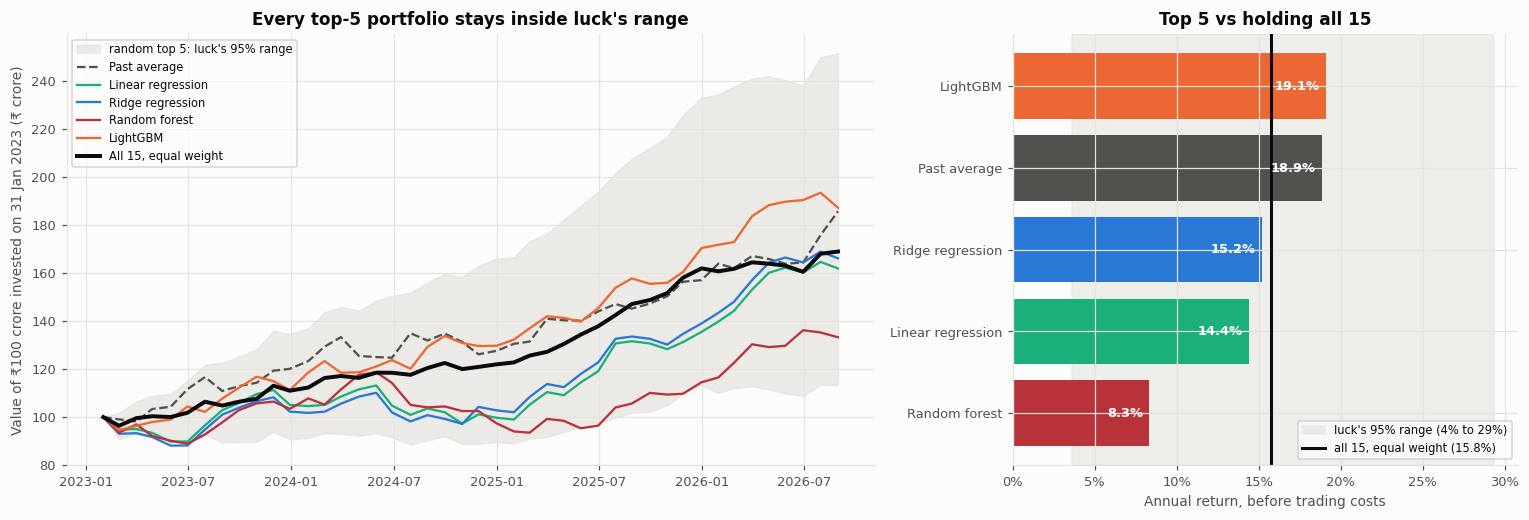

In [6]:
rng = np.random.default_rng(SEED)
R = pred.pivot(index="Date", columns="Ticker", values="Next_Month_Return").to_numpy()   # 43 months × 15 stocks


def random_portfolios(k: int, n: int = N_RANDOM) -> np.ndarray:
    """n random strategies: each month pick k of the 15 stocks at random, equal weight.
    Returns an (n × months) array of monthly returns."""
    months, stocks = R.shape
    # argsort of random numbers gives a random order of the 15 stocks for each run and month; keep the first k
    picks = np.argsort(rng.random((n, months, stocks)), axis=2)[:, :, :k]
    return np.take_along_axis(np.broadcast_to(R, (n, months, stocks)), picks, axis=2).mean(axis=2)


def annual_of(monthly_array: np.ndarray) -> np.ndarray:
    """Compounded annual return for each row of monthly returns."""
    return np.prod(1 + monthly_array, axis=1) ** (12 / monthly_array.shape[1]) - 1


random_runs = {k: random_portfolios(k) for k in K_CHECK}
random_annual = {k: annual_of(v) for k, v in random_runs.items()}
LUCK_LO, LUCK_HI = np.percentile(random_annual[TOP_K], [2.5, 97.5])

summary5["Share of random picks doing at least as well"] = [
    (1 + (random_annual[TOP_K] >= a).sum()) / (N_RANDOM + 1) if s != BENCH else np.nan
    for s, a in zip(summary5.Strategy, summary5["Annual return"])]
print(f"Random top {TOP_K} (1,000 runs): luck's 95% range of annual return {LUCK_LO:.1%} to {LUCK_HI:.1%}; "
      f"average {random_annual[TOP_K].mean():.1%} (≈ the benchmark's {BENCH_ANNUAL:.1%}, as it should be)")
display(summary5[["Strategy", "Annual return", "Excess a year", "p (excess)", "Share of random picks doing at least as well"]]
        .style.format({**FMT, "Share of random picks doing at least as well": "{:.0%}"}, na_rep="—").hide(axis="index"))

# Chart 1: growth of ₹100 crore, with luck's 95% band
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
x = [DATES[0]] + [held_until[d] for d in DATES]                 # start on 31 Jan 2023 at ₹100 crore


def path(monthly_r):
    """Value of ₹100 crore over time, starting at ₹100 crore on the first rebalance date."""
    return START_RUPEES_CRORE * np.concatenate([[1.0], np.cumprod(1 + np.asarray(monthly_r))])


band = np.array([path(r) for r in random_runs[TOP_K]])
ax.fill_between(x, np.percentile(band, 2.5, axis=0), np.percentile(band, 97.5, axis=0), color=GRID, alpha=0.7,
                label=f"random top {TOP_K}: luck's 95% range")
for name in STRATEGIES + [BENCH]:
    ax.plot(x, path(monthly[name]), color=COLOURS[name],
            lw=2.6 if name == BENCH else 1.5, ls="--" if name == "Past average" else "-", label=name)
ax.set_ylabel("Value of ₹100 crore invested on 31 Jan 2023 (₹ crore)")
ax.set_title(f"Every top-{TOP_K} portfolio stays inside luck's range")
ax.legend(fontsize=7.5, loc="upper left")
ax = axes[1]
order = summary5[summary5.Strategy != BENCH].sort_values("Annual return")
ax.barh(order.Strategy, order["Annual return"], color=[COLOURS[s] for s in order.Strategy])
ax.axvspan(LUCK_LO, LUCK_HI, color=GRID, alpha=0.6, zorder=0, label=f"luck's 95% range ({LUCK_LO:.0%} to {LUCK_HI:.0%})")
ax.axvline(BENCH_ANNUAL, color=INK, lw=2, label=f"all 15, equal weight ({BENCH_ANNUAL:.1%})")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
for i, v in enumerate(order["Annual return"]):
    ax.text(v - 0.004, i, f"{v:.1%}", va="center", ha="right", fontsize=8.5, color="white", fontweight="bold")
ax.set_xlabel("Annual return, before trading costs")
ax.set_title(f"Top {TOP_K} vs holding all 15")
ax.legend(fontsize=7.5, loc="lower right")
fig.tight_layout(); save_chart(fig, "01_portfolios_vs_luck"); plt.show()

## 6. Check: top 3 and top 7

**Why this check:** a real ranking skill helps whatever the number of stocks held: the best 3, 5 and 7 should all beat holding all 15, and fewer stocks should beat it by more (they are the model's strongest picks). If the "winner" changes with the number, the differences are noise.

In [7]:
tables = []
for k in K_CHECK:
    ranked_k = ranked.assign(Weight=np.where(ranked.Rank <= k, 1 / k, 0.0))
    monthly_k = pd.DataFrame({n: portfolio_returns(ranked_k[ranked_k.Strategy == n]) for n in STRATEGIES})
    monthly_k[BENCH] = monthly[BENCH]
    t = summary_table(monthly_k, ranked_k, k)
    lo, hi = np.percentile(random_annual[k], [2.5, 97.5])
    t["Luck's 95% range"] = f"{lo:.1%} to {hi:.1%}"
    tables.append(t[t.Strategy != BENCH])
size_check = pd.concat(tables, ignore_index=True)

wide = size_check.pivot(index="Strategy", columns="Stocks held", values="Annual return").reindex(STRATEGIES)
wide_p = size_check.pivot(index="Strategy", columns="Stocks held", values="p (excess)").reindex(STRATEGIES)
show = wide.map(lambda v: f"{v:.1%}") + "  (p " + wide_p.map(lambda v: f"{v:.2f}") + ")"
show.columns = [f"Top {k}" for k in show.columns]
show.loc[BENCH] = f"{BENCH_ANNUAL:.1%}"
show.loc["Luck's 95% range (random picks)"] = [f"{np.percentile(random_annual[k], 2.5):.1%} to "
                                               f"{np.percentile(random_annual[k], 97.5):.1%}" for k in K_CHECK]
print("Annual return (p for the excess over all 15), before trading costs")
display(show)
best = wide.idxmax()
print("Best strategy at each size:", ", ".join(f"top {k}: {best[k]}" for k in K_CHECK))
print("Smallest p anywhere:", f"{size_check['p (excess)'].min():.2f}", f"(line {LINE:.3f})")

Annual return (p for the excess over all 15), before trading costs


,Top 3,Top 5,Top 7
Strategy,,,
Past average,25.6% (p 0.31),18.9% (p 0.60),12.6% (p 0.53)
Linear regression,9.5% (p 0.54),14.4% (p 0.92),19.8% (p 0.43)
Ridge regression,9.1% (p 0.50),15.2% (p 0.98),20.3% (p 0.38)
Random forest,5.8% (p 0.35),8.3% (p 0.40),9.8% (p 0.35)
LightGBM,19.9% (p 0.60),19.1% (p 0.57),11.7% (p 0.46)
"All 15, equal weight",15.8%,15.8%,15.8%
Luck's 95% range (random picks),-2.6% to 33.7%,3.6% to 29.3%,5.7% to 25.6%


Best strategy at each size: top 3: Past average, top 5: LightGBM, top 7: Ridge regression
Smallest p anywhere: 0.31 (line 0.010)


## 7. Concentration and risk: 5 stocks vs 15

Holding fewer stocks puts more weight on each one, so the portfolio swings more. How much depends on how closely the stocks move together:

```text
If stocks moved independently:  portfolio volatility ≈ one stock's volatility ÷ √(number of stocks)
  e.g. one stock 30% a year →  5 stocks: 30% ÷ √5 ≈ 13.4%   15 stocks: 30% ÷ √15 ≈ 7.7%
```

In this data the stocks barely move together (average correlation 0.004, Task 1; real large-caps: 0.3–0.5), so the formula fits closely. The chart shows random portfolios of every size from 1 to 15 stocks, with the formula and the five top-5 strategies.

Average single stock: volatility 29.7% a year
All 15 equal weight: 6.7%;  top-5 strategies: 10.9% to 13.2%  → about 1.8 times the risk of holding all 15


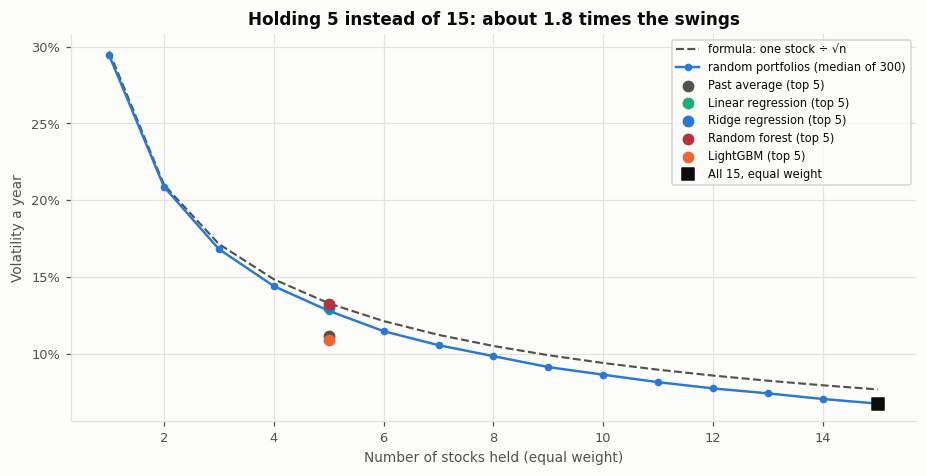

In [8]:
stock_vol = float(pred.groupby("Ticker").Next_Month_Return.std().mean() * np.sqrt(12))   # average single stock
sizes = range(1, 16)
random_vol = [float(np.median(random_portfolios(k, 300).std(axis=1, ddof=1) * np.sqrt(12))) for k in sizes]
risk = pd.DataFrame({"Stocks held": list(sizes), "Formula: one stock ÷ √n": [stock_vol / np.sqrt(k) for k in sizes],
                     "Random portfolios (median)": random_vol})
vol5 = summary5.set_index("Strategy").loc[STRATEGIES, "Volatility"]
vol15 = float(summary5.set_index("Strategy").loc[BENCH, "Volatility"])
print(f"Average single stock: volatility {stock_vol:.1%} a year")
print(f"All 15 equal weight: {vol15:.1%};  top-5 strategies: {vol5.min():.1%} to {vol5.max():.1%}  "
      f"→ about {vol5.mean() / vol15:.1f} times the risk of holding all 15")

fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.plot(risk["Stocks held"], risk["Formula: one stock ÷ √n"], color=INK_2, ls="--", lw=1.4, label="formula: one stock ÷ √n")
ax.plot(risk["Stocks held"], risk["Random portfolios (median)"], color=BLUE, marker="o", ms=4, lw=1.6, label="random portfolios (median of 300)")
for name in STRATEGIES:
    ax.scatter(TOP_K, vol5[name], color=COLOURS[name], s=45, zorder=3, label=f"{name} (top {TOP_K})")
ax.scatter(15, vol15, color=INK, s=60, marker="s", zorder=3, label=BENCH)
ax.set_xlabel("Number of stocks held (equal weight)"); ax.set_ylabel("Volatility a year")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title(f"Holding {TOP_K} instead of 15: about {vol5.mean() / vol15:.1f} times the swings")
ax.legend(fontsize=7.5)
fig.tight_layout(); save_chart(fig, "02_concentration_risk"); plt.show()

## 8. What it means in ₹

₹100 crore invested on 31 Jan 2023 in each portfolio, rebalanced every month-end, valued on 31 Aug 2026 (43 months), **before trading costs**:

```text
Value at the end       = ₹100 crore × growth of ₹1
Gain vs all 15         = value − the benchmark's value
Gap a year (₹ crore)   = (annual return − benchmark's annual return) × ₹100 crore
```

**Trading costs (left to Module 6, decision M5-13):** each month the models replace about half of their 5 stocks. Every replacement is a sale and a purchase, so the cost a year is roughly turnover × 2 × 12 × the cost of one trade. Module 6 sets that cost rate; it can only lower these returns.

In [9]:
money = summary5[["Strategy", "Annual return", "Growth of ₹1", "Excess a year", "p (excess)"]].copy()
money["Value on 31 Aug 2026 (₹ crore)"] = START_RUPEES_CRORE * money["Growth of ₹1"]
bench_value = float(money.set_index("Strategy").loc[BENCH, "Value on 31 Aug 2026 (₹ crore)"])
money["Gain vs all 15 (₹ crore)"] = money["Value on 31 Aug 2026 (₹ crore)"] - bench_value
money["Gap a year (₹ crore)"] = money["Excess a year"] * START_RUPEES_CRORE
money["Turnover a month"] = summary5["Turnover a month"]
money["Trades a year (sales + purchases, share of the portfolio)"] = money["Turnover a month"] * 2 * 12
display(money.drop(columns=["Growth of ₹1"]).style.format(
    {"Annual return": "{:.1%}", "Excess a year": "{:+.1%}", "p (excess)": "{:.2f}",
     "Value on 31 Aug 2026 (₹ crore)": "₹{:.1f}", "Gain vs all 15 (₹ crore)": "₹{:+.1f}",
     "Gap a year (₹ crore)": "₹{:+.1f}", "Turnover a month": "{:.0%}",
     "Trades a year (sales + purchases, share of the portfolio)": "{:.0%}"}, na_rep="—").hide(axis="index"))
print(f"Luck's 95% range for a random top {TOP_K}, in ₹: "
      f"₹{START_RUPEES_CRORE * (1 + LUCK_LO) ** (len(DATES) / 12):.0f} to ₹{START_RUPEES_CRORE * (1 + LUCK_HI) ** (len(DATES) / 12):.0f} crore "
      f"(benchmark ₹{bench_value:.0f} crore)")

Strategy,Annual return,Excess a year,p (excess),Value on 31 Aug 2026 (₹ crore),Gain vs all 15 (₹ crore),Gap a year (₹ crore),Turnover a month,"Trades a year (sales + purchases, share of the portfolio)"
Past average,18.9%,+3.1%,0.60,₹185.7,₹+16.8,₹+3.1,10%,229%
Linear regression,14.4%,-1.4%,0.92,₹161.9,₹-7.0,₹-1.4,49%,1166%
Ridge regression,15.2%,-0.5%,0.98,₹166.1,₹-2.8,₹-0.5,48%,1143%
Random forest,8.3%,-7.4%,0.40,₹133.2,₹-35.7,₹-7.4,58%,1383%
LightGBM,19.1%,+3.4%,0.57,₹187.2,₹+18.2,₹+3.4,68%,1634%
"All 15, equal weight",15.8%,—,—,₹169.0,₹+0.0,—,—,—


Luck's 95% range for a random top 5, in ₹: ₹113 to ₹251 crore (benchmark ₹169 crore)


## 9. The portfolio for September 2026: every strategy's picks on the latest rebalance date

The brief says "for every rebalance date". The last one, **31 Aug 2026**, is the date NovaFin would actually act on: *what do we hold in September?* Steps 1–8 stop at 31 Jul 2026 because September's result is not in the data, so it can't be scored.

**How:** each model is trained on **all 67 months** with a known next-month return (Feb 2021 – Aug 2026), with the same inputs and settings as Task 1 (decisions M5-07, M5-08). It then predicts September for the 15 stocks using the inputs known on 31 Aug 2026. Then rank → top 5 → 20% each, as in steps 2–4.

**Read with care:**
- No model has shown ranking skill (Task 1), and no top-5 portfolio beat holding all 15 beyond luck (steps 4–6). These are the models' picks, not a recommendation. **The evidence points to holding all 15.**
- These picks can't be used to choose a model: there is no September result to judge them by.
- **Agreement between models:** two lists of 5 drawn at random from 15 share 5 × 5 ÷ 15 ≈ 1.7 stocks on average. Sharing more does **not** by itself show a real signal: models fed the same inputs pick up the same noise. So September's overlap is compared with the overlap over the 43 test months, when the models shared picks but still didn't beat luck.

In [10]:
MODEL_NAMES = ["Linear regression", "Ridge regression", "Random forest", "LightGBM"]


def make_model(name):
    """A fresh, untrained model with Task 1's agreed settings (decision M5-08)."""
    if name == "Linear regression":
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression())
    if name == "Ridge regression":
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10))
    if name == "Random forest":
        return make_pipeline(SimpleImputer(strategy="median"),
                             RandomForestRegressor(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=SEED))
    return lgb.LGBMRegressor(n_estimators=200, num_leaves=4, learning_rate=0.05, min_child_samples=20,
                             random_state=SEED, verbose=-1)


def predict_all(train: pd.DataFrame, target_rows: pd.DataFrame, cols: list) -> dict:
    """Train every ranker on `train` and predict `target_rows`. Returns {strategy: predictions}."""
    out = {"Past average": target_rows.Ticker.map(train.groupby("Ticker").Next_Month_Return.mean()).values}
    for name in MODEL_NAMES:
        out[name] = make_model(name).fit(train[cols], train.Next_Month_Return).predict(target_rows[cols])
    return out


mkt = load_market()
panel = monthly_panel(mkt)                                   # 67 months with a known next-month return
SECTOR_COLS = [c for c in panel if c.startswith("Sec_")]
X_COLS = INPUTS + SECTOR_COLS                                # 13 inputs + sector (decision M5-07)
LIVE_DATE = month_end_dates(mkt)[-1]                         # 31 Aug 2026
live = add_features(mkt)
live = live[live.Date == LIVE_DATE].sort_values("Ticker").reset_index(drop=True)
live = pd.concat([live, pd.get_dummies(live.Sector, prefix="Sec", dtype=float).reindex(columns=SECTOR_COLS, fill_value=0.0)], axis=1)
print(f"Training: {panel.Date.nunique()} months × 15 stocks = {len(panel):,} rows; predicting for {LIVE_DATE:%d %b %Y} (held to 30 Sep 2026)")

live_pred = predict_all(panel, live, X_COLS)
rows = []
for name in STRATEGIES:
    f = live[["Ticker", "Sector"]].assign(**{"Predicted return": live_pred[name]})
    f["Rank"] = f["Predicted return"].rank(ascending=False, method="first").astype(int)
    f["Strategy"] = name
    rows.append(f)
live_all = pd.concat(rows, ignore_index=True)
live_all["Selected"] = np.where(live_all.Rank <= TOP_K, "Yes", "No")
live_all["Weight"] = np.where(live_all.Rank <= TOP_K, 1 / TOP_K, 0.0)

picks = (live_all[live_all.Rank <= TOP_K].sort_values(["Strategy", "Rank"])
         .assign(Pick=lambda d: d.Ticker + " (" + d["Predicted return"].map("{:+.1%}".format) + ")")
         .pivot(index="Rank", columns="Strategy", values="Pick")[STRATEGIES])
print(f"Top {TOP_K} for September 2026 (predicted next-month return in brackets), 20% each:")
display(picks)

# How many strategies pick each stock, and how much the lists overlap
chosen = {n: set(live_all[(live_all.Strategy == n) & (live_all.Rank <= TOP_K)].Ticker) for n in STRATEGIES}
votes = pd.Series([t for n in STRATEGIES for t in chosen[n]]).value_counts()
print("\nHow many of the 5 strategies pick each stock:", ", ".join(f"{t} {v}" for t, v in sorted(votes.items(), key=lambda x: (-x[1], x[0]))))     # ties in name order, so every run prints the same
pairs = [(a, b) for i, a in enumerate(MODEL_NAMES) for b in MODEL_NAMES[i + 1:]]
live_overlap = float(np.mean([len(chosen[a] & chosen[b]) for a, b in pairs]))


def month_overlap(a, b):
    """Average number of shared top-5 stocks between strategies a and b over the 43 test months."""
    sa = ranked[(ranked.Strategy == a) & (ranked.Rank <= TOP_K)].groupby("Date").Ticker.apply(set)
    sb = ranked[(ranked.Strategy == b) & (ranked.Rank <= TOP_K)].groupby("Date").Ticker.apply(set)
    return float(np.mean([len(x & y) for x, y in zip(sa, sb)]))


past_overlap = pd.DataFrame([{"Pair": f"{a} & {b}", "Shared stocks, Sep 2026": len(chosen[a] & chosen[b]),
                              "Shared stocks, average of 43 months": month_overlap(a, b)} for a, b in pairs])
print(f"Average stocks shared by two ML models: September 2026 {live_overlap:.1f}; "
      f"43 test months {past_overlap['Shared stocks, average of 43 months'].mean():.1f}; random lists 1.7")
display(past_overlap.style.format({"Shared stocks, average of 43 months": "{:.1f}"}).hide(axis="index"))

Training: 67 months × 15 stocks = 1,005 rows; predicting for 31 Aug 2026 (held to 30 Sep 2026)


Top 5 for September 2026 (predicted next-month return in brackets), 20% each:


Strategy,Past average,Linear regression,Ridge regression,Random forest,LightGBM
Rank,,,,,
1,ICICIBANK (+3.0%),LT (+3.5%),LT (+3.5%),LT (+3.9%),LT (+5.6%)
2,INFY (+2.5%),HDFCBANK (+1.9%),HDFCBANK (+2.0%),BHARTIARTL (+2.5%),SBIN (+3.7%)
3,RELIANCE (+2.0%),ITC (+1.7%),ITC (+1.7%),ITC (+2.4%),ITC (+3.1%)
4,HINDUNILVR (+1.8%),TITAN (+1.6%),TITAN (+1.6%),SBIN (+1.9%),TCS (+2.9%)
5,SUNPHARMA (+1.4%),AXISBANK (+1.1%),AXISBANK (+1.2%),HDFCBANK (+1.9%),ICICIBANK (+2.2%)



How many of the 5 strategies pick each stock: ITC 4, LT 4, HDFCBANK 3, AXISBANK 2, ICICIBANK 2, SBIN 2, TITAN 2, BHARTIARTL 1, HINDUNILVR 1, INFY 1, RELIANCE 1, SUNPHARMA 1, TCS 1
Average stocks shared by two ML models: September 2026 3.0; 43 test months 2.9; random lists 1.7


Pair,"Shared stocks, Sep 2026","Shared stocks, average of 43 months"
Linear regression & Ridge regression,5,4.9
Linear regression & Random forest,3,2.6
Linear regression & LightGBM,2,2.1
Ridge regression & Random forest,3,2.6
Ridge regression & LightGBM,2,2.1
Random forest & LightGBM,3,3.1


## 10. Two more checks: quarterly rebalancing, and other ways of weighting the top 5

**10a. Quarterly instead of monthly?** Companies report results every quarter, so a quarterly rebalance is a natural alternative. This data has no earnings or report dates, so that reason can't be used here, but the horizon can still be tested:
- the 22 inputs against the next quarter's return (line 0.05 ÷ 22 = 0.0023);
- the five rankers walk-forward on quarter-ends: train on all earlier quarters, predict the next; test quarters from Mar 2023, so the first 8 quarters train only (the same two years as monthly);
- the smallest edge the test can detect = 2 × month-to-month (here quarter-to-quarter) spread of IC ÷ √(test periods), as in decision M5-04.

**10b. Weighting the top 5 by the model's confidence?** Equal weight says "no view on which of the 5 is best". Two alternatives that put more money behind the strongest predictions:
- **by rank:** 33%, 27%, 20%, 13%, 7% for ranks 1–5 (5, 4, 3, 2, 1 parts out of 15);
- **by predicted return:** each stock's weight ∝ how far its prediction is above the 6th-ranked stock's.

If the predictions carried skill, these would earn more than equal weight. Optimised weights (Markowitz) remain Module 6's comparison.

In [11]:
# ---- 10a. Quarterly ----
me = month_end_dates(mkt)
qe = me[me.month.isin([3, 6, 9, 12])]                                   # quarter-ends
feats = add_features(mkt)
qpanel = feats[feats.Date.isin(qe)].merge(forward_returns(mkt, qe), on=["Date", "Ticker"]).dropna(subset=["Next_Month_Return"])
qpanel = pd.concat([qpanel.reset_index(drop=True),
                    pd.get_dummies(qpanel.Sector, prefix="Sec", dtype=float).reindex(columns=SECTOR_COLS, fill_value=0.0).reset_index(drop=True)], axis=1)
# (Next_Month_Return here holds the return to the next QUARTER-end: forward_returns works on any list of dates.)
QDATES = sorted(qpanel.Date.unique())
Q_TEST = [d for d in QDATES if d >= pd.Timestamp("2023-01-01")]


def ic_by_date(frame, col):
    """IC for each date: rank correlation between `col` and the next-period return across the 15 stocks."""
    return frame.groupby("Date").apply(lambda x: stats.spearmanr(x[col], x.Next_Month_Return).correlation
                                       if x[col].nunique() > 1 else np.nan).dropna()


q_inputs = pd.DataFrame([{"Input": c, "IC": ic_by_date(qpanel, c).mean(), "p": stats.ttest_1samp(ic_by_date(qpanel, c), 0).pvalue}
                         for c in ALL_INPUTS]).sort_values("p")
Q_LINE = 0.05 / len(ALL_INPUTS)
print(f"Quarter-ends with a next quarter: {len(QDATES)}; test quarters: {len(Q_TEST)}")
print(f"22 inputs vs next quarter: {(q_inputs.p < Q_LINE).sum()} pass the line {Q_LINE:.4f}; smallest p {q_inputs.p.min():.3f} ({q_inputs.iloc[0].Input})")

q_preds = {n: [] for n in STRATEGIES}
for d in Q_TEST:
    train, test = qpanel[qpanel.Date < d], qpanel[qpanel.Date == d]   # the previous quarter's return is known on d
    for n, v in predict_all(train, test, X_COLS).items():
        q_preds[n].append(pd.Series(v, index=test.index))
qtest = qpanel[qpanel.Date.isin(Q_TEST)].copy()
q_all15 = qtest.groupby("Date").Next_Month_Return.mean()
annual_q = lambda r: float((1 + r).prod() ** (4 / len(r)) - 1)       # 4 quarters a year
q_rows, q_sd = [], []
for n in STRATEGIES:
    qtest[n] = pd.concat(q_preds[n])
    ic = ic_by_date(qtest, n)
    q_sd.append(ic.std())
    top = qtest[qtest.groupby("Date")[n].rank(ascending=False, method="first") <= TOP_K].groupby("Date").Next_Month_Return.mean()
    q_rows.append({"Strategy": n, "IC": ic.mean(), "Annual return, top 5": annual_q(top),
                   "p (excess)": float(stats.ttest_1samp(top - q_all15, 0).pvalue)})
quarterly = pd.DataFrame(q_rows)
Q_DETECT = 2 * float(np.mean(q_sd)) / np.sqrt(len(Q_TEST))
print(f"All 15, equal weight, quarterly: {annual_q(q_all15):.1%} a year over the same {len(Q_TEST)} quarters")
print(f"Smallest IC the quarterly test could detect ≈ 2 × {np.mean(q_sd):.2f} ÷ √{len(Q_TEST)} = {Q_DETECT:.2f} (monthly: about 0.08)")
display(quarterly.style.format({"IC": "{:+.3f}", "Annual return, top 5": "{:.1%}", "p (excess)": "{:.2f}"}).hide(axis="index"))

# ---- 10b. Weighting ----
def weighted_returns(name: str, how: str) -> pd.Series:
    """Monthly return of the top 5 weighted 'equal', 'rank' (5,4,3,2,1 ÷ 15) or 'pred' (∝ prediction above the 6th)."""
    f = ranked[ranked.Strategy == name]
    top = f[f.Rank <= TOP_K].copy()
    if how == "equal":
        top["w"] = 1 / TOP_K
    elif how == "rank":
        top["w"] = (TOP_K + 1 - top.Rank) / (TOP_K * (TOP_K + 1) / 2)
    else:
        sixth = f[f.Rank == TOP_K + 1].set_index("Date")["Predicted return"]
        edge = top["Predicted return"] - top.Date.map(sixth) + 1e-9      # always ≥ 0 (top 5 are above the 6th)
        top["w"] = edge / edge.groupby(top.Date).transform("sum")
    return (top.w * top.Next_Month_Return).groupby(top.Date).sum()


w_rows = []
for n in STRATEGIES:
    for how, label in [("equal", "Equal (20% each)"), ("rank", "By rank (33/27/20/13/7%)"), ("pred", "By predicted return")]:
        r = weighted_returns(n, how)
        w_rows.append({"Strategy": n, "Weighting": label, "Annual return": performance(r)["Annual return"],
                       "Volatility": performance(r)["Volatility"],
                       "p (excess)": float(stats.ttest_1samp(r - monthly[BENCH], 0).pvalue)})
weighting = pd.DataFrame(w_rows)
wt = weighting.pivot(index="Strategy", columns="Weighting", values="Annual return").reindex(STRATEGIES)
wt = wt[["Equal (20% each)", "By rank (33/27/20/13/7%)", "By predicted return"]]
print(f"Annual return of the top 5 by weighting (all 15 equal weight: {BENCH_ANNUAL:.1%}); smallest p {weighting['p (excess)'].min():.2f} (line {LINE:.3f})")
display(wt.style.format("{:.1%}"))
heavy = weighting[weighting.Weighting == "By predicted return"].set_index("Strategy")
print("Volatility, by predicted return:", ", ".join(f"{n} {heavy.loc[n, 'Volatility']:.1%}" for n in STRATEGIES))

Quarter-ends with a next quarter: 21; test quarters: 13
22 inputs vs next quarter: 0 pass the line 0.0023; smallest p 0.019 (VIX)


All 15, equal weight, quarterly: 14.9% a year over the same 13 quarters
Smallest IC the quarterly test could detect ≈ 2 × 0.28 ÷ √13 = 0.16 (monthly: about 0.08)


Strategy,IC,"Annual return, top 5",p (excess)
Past average,-0.045,20.8%,0.33
Linear regression,-0.084,6.5%,0.22
Ridge regression,-0.091,7.6%,0.33
Random forest,+0.062,15.1%,0.91
LightGBM,+0.090,24.9%,0.08


Annual return of the top 5 by weighting (all 15 equal weight: 15.8%); smallest p 0.18 (line 0.010)


Weighting,Equal (20% each),By rank (33/27/20/13/7%),By predicted return
Strategy,,,
Past average,18.9%,25.7%,29.5%
Linear regression,14.4%,10.2%,7.7%
Ridge regression,15.2%,11.8%,8.6%
Random forest,8.3%,7.4%,7.8%
LightGBM,19.1%,16.5%,12.3%


Volatility, by predicted return: Past average 17.6%, Linear regression 15.0%, Ridge regression 15.0%, Random forest 15.0%, LightGBM 15.3%


## 11. Stock by stock: the scorecard

Steps 4–10 judge **portfolios**. This step looks at each of the 15 **stocks**: how each did over the test period (31 Jan 2023 – 31 Aug 2026), whether winners stayed winners, how often each model picked it, and whether ridge's forecasts tracked it (decision M5-18).

**The columns, in plain words:**
- **Yearly return** (CAGR: steady yearly growth), **yearly swing** (volatility: sd of daily returns × √261), **return per unit of risk** (yearly return ÷ swing, as in step 4), **worst fall** (from a previous high).
- **First half / second half:** the yearly return over the first and second half of the 934 test days. **2021–22:** the yearly return before the test period. If winners stayed winners, these would rank the stocks the same way.
- **Months in the top 5:** out of 43, for each model. An even spread is 43 × 5 ÷ 15 ≈ 14.
- **Forecast-tracking (ridge):** correlation between ridge's monthly forecasts for that stock and its actual returns (−1 to +1; 0 = no link).
- **September 2026 picks:** how many of the 5 strategies put it in their top 5 for September (step 9).

**Luck test of the spread:** 15 simulated stocks with the same average return and swing, 2,000 times. If the real best-to-worst spread (sd of the 15 yearly returns) falls inside luck's range, the winners and losers are what chance produces.

Spread of the 15 yearly returns (sd): 15.5%; luck's 95% range 10.4% to 23.5%
Did winners stay winners? Rank correlation (+1 = same order, 0 = unrelated): first half vs second half -0.08 (p 0.77); 2021–22 vs test period +0.45 (p 0.10; 15 stocks, so p must be below 0.05 to count)
Yearly swing ranges only 27.9% to 30.6%: the stocks are equally risky


Rank (best = 1),Ticker,Sector,Yearly return,Yearly swing,Worst fall,First half (yearly),Second half (yearly),Months in top 5: Ridge regression,Forecast-tracking (ridge),September 2026 picks (of 5 strategies)
1,ICICIBANK,Banking,+45.0%,29.3%,-24.8%,+77.5%,+18.5%,12,-0.07,2
2,INFY,IT,+37.4%,28.7%,-18.5%,+43.0%,+32.0%,11,-0.01,1
3,HINDUNILVR,Consumer,+28.7%,30.6%,-21.9%,+11.3%,+48.7%,16,-0.14,1
4,RELIANCE,Energy,+25.8%,29.9%,-32.6%,+19.7%,+32.3%,31,+0.03,1
5,KOTAKBANK,Banking,+17.9%,30.3%,-47.2%,-7.5%,+50.4%,16,+0.03,0
6,AXISBANK,Banking,+17.6%,29.0%,-43.1%,+0.0%,+38.2%,9,-0.11,2
7,SUNPHARMA,Healthcare,+11.3%,28.9%,-38.8%,-5.9%,+31.7%,17,+0.15,1
8,HDFCBANK,Banking,+4.7%,28.7%,-30.5%,+17.4%,-6.6%,13,+0.09,3
9,TCS,IT,+2.8%,28.7%,-37.1%,-16.2%,+26.0%,18,-0.11,1
10,MARUTI,Auto,+2.5%,28.6%,-48.5%,-18.8%,+29.3%,4,+0.03,0


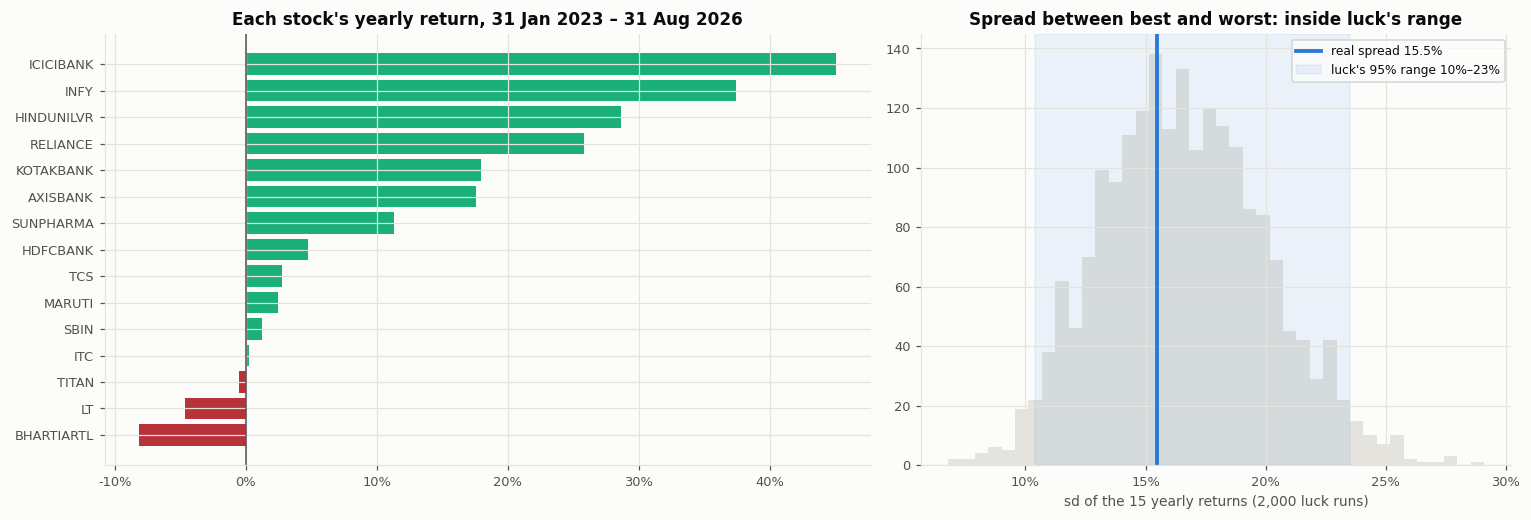

In [12]:
from m05_data import load_market as _lm                    # already loaded as mkt in step 9; kept explicit
DAILY = mkt.pivot(index="Date", columns="Ticker", values="Return").sort_index()
TEST = DAILY.loc[(DAILY.index > DATES[0]) & (DAILY.index <= pd.Timestamp("2026-08-31"))]
EARLY = DAILY.loc[:pd.Timestamp("2022-12-31")]
YEAR = 261                                                  # trading rows a year in this data (every weekday)
half = len(TEST) // 2


def cagr_d(r):
    """Steady yearly growth from daily returns: (end ÷ start) ^ (261 ÷ days) − 1."""
    return float((1 + r).prod() ** (YEAR / len(r)) - 1)


def worst_fall(r):
    v = pd.concat([pd.Series([1.0]), (1 + r).cumprod().reset_index(drop=True)])
    return float((v / v.cummax() - 1).min())


sector_of = pred.drop_duplicates("Ticker").set_index("Ticker").Sector
month_avg = pred.groupby("Date").Next_Month_Return.mean()
rows = []
for t in TEST.columns:
    r = TEST[t]
    p_t = pred[pred.Ticker == t].sort_values("Date")
    row = {"Ticker": t, "Sector": sector_of[t], "Yearly return": cagr_d(r),
           "Yearly swing": float(r.std() * np.sqrt(YEAR)), "Worst fall": worst_fall(r),
           "First half (yearly)": cagr_d(r.iloc[:half]), "Second half (yearly)": cagr_d(r.iloc[half:]),
           "2021–22 (yearly)": cagr_d(EARLY[t]),
           "Average month vs the 15-stock average": float((p_t.set_index("Date").Next_Month_Return - month_avg).mean()),
           "Forecast-tracking (ridge)": float(np.corrcoef(p_t["Pred: Ridge regression"], p_t.Next_Month_Return)[0, 1]),
           "September 2026 picks (of 5 strategies)": int(sum(t in chosen[n] for n in STRATEGIES))}
    row["Return per unit of risk"] = row["Yearly return"] / row["Yearly swing"]
    for n in STRATEGIES:
        row[f"Months in top 5: {n}"] = int(((ranked.Strategy == n) & (ranked.Ticker == t) & (ranked.Rank <= TOP_K)).sum())
    rows.append(row)
scorecard = pd.DataFrame(rows).sort_values("Yearly return", ascending=False).reset_index(drop=True)
scorecard.insert(0, "Rank (best = 1)", range(1, 16))


def in_words(r):
    """One sentence per stock: where it ranked, how its halves compared, whether the models caught it."""
    place = "Best stock" if r["Rank (best = 1)"] == 1 else ("Worst stock" if r["Rank (best = 1)"] == 15 else f"Rank {r['Rank (best = 1)']} of 15")
    halves = (f"first half {r['First half (yearly)']:+.1%}, second half {r['Second half (yearly)']:+.1%}"
              + ("; stayed strong" if min(r['First half (yearly)'], r['Second half (yearly)']) > 0.1
                 else "; reversed" if (r['First half (yearly)'] > 0) != (r['Second half (yearly)'] > 0) else ""))
    track = r["Forecast-tracking (ridge)"]
    return (f"{place}: {r['Yearly return']:+.1%} a year ({halves}). Ridge put it in its top 5 in "
            f"{r['Months in top 5: Ridge regression']} of 43 months; its forecasts "
            + ("ran opposite to" if track < -0.05 else "barely tracked" if track < 0.1 else "loosely tracked")
            + f" the stock's actual returns ({track:+.2f}). No input in the data explains its result (Task 1).")


scorecard["What happened, in words"] = scorecard.apply(in_words, axis=1)

# Luck test of the spread between stocks
rng_s = np.random.default_rng(SEED)
mu_all, sd_all = TEST.values.mean(), TEST.values.std()
sim_sd = [np.std((1 + rng_s.normal(mu_all, sd_all, (len(TEST), 15))).prod(axis=0) ** (YEAR / len(TEST)) - 1)
          for _ in range(2000)]
SPREAD_REAL = float(scorecard["Yearly return"].std(ddof=0))
SPREAD_LO, SPREAD_HI = np.percentile(sim_sd, [2.5, 97.5])
persist, persist_p = stats.spearmanr(scorecard["First half (yearly)"], scorecard["Second half (yearly)"])
persist_early, persist_early_p = stats.spearmanr(scorecard["2021–22 (yearly)"], scorecard["Yearly return"])
print(f"Spread of the 15 yearly returns (sd): {SPREAD_REAL:.1%}; luck's 95% range {SPREAD_LO:.1%} to {SPREAD_HI:.1%}")
print(f"Did winners stay winners? Rank correlation (+1 = same order, 0 = unrelated): first half vs second half {persist:+.2f} (p {persist_p:.2f}); "
      f"2021–22 vs test period {persist_early:+.2f} (p {persist_early_p:.2f}; 15 stocks, so p must be below 0.05 to count)")
print(f"Yearly swing ranges only {scorecard['Yearly swing'].min():.1%} to {scorecard['Yearly swing'].max():.1%}: the stocks are equally risky")
show_cols = ["Rank (best = 1)", "Ticker", "Sector", "Yearly return", "Yearly swing", "Worst fall", "First half (yearly)",
             "Second half (yearly)", "Months in top 5: Ridge regression", "Forecast-tracking (ridge)", "September 2026 picks (of 5 strategies)"]
display(scorecard[show_cols].style.format({c: "{:+.1%}" for c in ["Yearly return", "Worst fall", "First half (yearly)", "Second half (yearly)"]}
                                          | {"Yearly swing": "{:.1%}", "Forecast-tracking (ridge)": "{:+.2f}"}).hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
sc = scorecard.iloc[::-1]
ax.barh(sc.Ticker, sc["Yearly return"], color=[GAIN if v > 0 else LOSS for v in sc["Yearly return"]])
ax.axvline(0, color=INK_2, lw=1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Each stock's yearly return, 31 Jan 2023 – 31 Aug 2026")
ax = axes[1]
ax.hist(sim_sd, bins=40, color=GRID)
ax.axvline(SPREAD_REAL, color=BLUE, lw=2.5, label=f"real spread {SPREAD_REAL:.1%}")
ax.axvspan(SPREAD_LO, SPREAD_HI, color=BLUE, alpha=0.08, label=f"luck's 95% range {SPREAD_LO:.0%}–{SPREAD_HI:.0%}")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Spread between best and worst: inside luck's range")
ax.set_xlabel("sd of the 15 yearly returns (2,000 luck runs)")
ax.legend(fontsize=8)
fig.tight_layout(); save_chart(fig, "03_stock_scorecard"); plt.show()

## 12. What the results say

**Answer for Task 2: no top-5 portfolio beats simply holding all 15 stocks beyond luck.** The differences are what luck produces, and holding 5 stocks carries about 1.8 times the risk.

**Reminder of the measures:**
- **Annual return:** yearly growth rate, compounded. The benchmark (all 15, equal weight) made **15.8%**.
- **p (excess):** the chance luck alone gives a monthly excess over the benchmark at least this far from 0. **Range 0 to 1;** the line is 0.05 ÷ 5 strategies = **0.01**.
- **Share of random picks doing at least as well:** of 1,000 portfolios of 5 random stocks a month, how many did as well or better. About 50% = what luck does; below 1% would mean real skill.
- **Volatility:** size of the swings a year; lower is calmer. **Return per unit of risk** = annual return ÷ volatility; higher is better.
- **Maximum drawdown:** the worst fall from a previous high; closer to 0 is better.
- **Turnover:** share of the 5 stocks replaced each month; every replacement costs money.

### Top 5, equal weight, before trading costs (31 Jan 2023 – 31 Aug 2026, 43 months)

| Strategy | Annual return | Excess a year | p (excess) | Months beating all 15 (of 43) | Random picks doing as well | Volatility | Return per unit of risk | Maximum drawdown | Turnover a month |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Past average (benchmark) | 18.9% | +3.1% | 0.60 | 23 | 28% | 11.2% | 1.69 | −6.5% | 10% |
| Linear regression | 14.4% | −1.4% | 0.92 | 20 | 53% | 13.0% | 1.11 | −14.1% | 49% |
| Ridge regression | 15.2% | −0.5% | 0.98 | 20 | 47% | 13.0% | 1.17 | −11.9% | 48% |
| Random forest | 8.3% | −7.4% | 0.40 | 17 | 87% | 13.3% | 0.63 | −21.2% | 58% |
| LightGBM | 19.1% | +3.4% | 0.57 | 24 | 27% | 10.9% | 1.75 | −5.4% | 68% |
| **All 15, equal weight** | **15.8%** | — | — | — | — | **6.7%** | **2.34** | **−3.6%** | — |

- **No strategy beats the benchmark beyond luck.** The smallest p is 0.40 (line 0.01). The months beating all 15 are 17–24 of 43, around the 21–22 a coin toss gives.
- **Luck alone spans every result.** Random top-5 portfolios made **3.6% to 29.3%** a year (95% range). Every strategy sits inside it; the best two (LightGBM, past average) were matched or beaten by about 27–28% of random picks.
- **Holding all 15 gives the best return per unit of risk** (2.34, against 0.63–1.75 for any top 5). It also had the smallest worst fall (−3.6%).
- **The ranking matches Task 1.** Random forest had the most negative IC (−0.049) and the worst portfolio (8.3%); the others are close to the benchmark, as an IC near 0 implies.

### Check: top 3 and top 7 (step 6)

| Strategy | Top 3 | Top 5 | Top 7 |
| --- | --- | --- | --- |
| Past average | 25.6% (p 0.31) | 18.9% (p 0.60) | 12.6% (p 0.53) |
| Linear regression | 9.5% (p 0.54) | 14.4% (p 0.92) | 19.8% (p 0.43) |
| Ridge regression | 9.1% (p 0.50) | 15.2% (p 0.98) | 20.3% (p 0.38) |
| Random forest | 5.8% (p 0.35) | 8.3% (p 0.40) | 9.8% (p 0.35) |
| LightGBM | 19.9% (p 0.60) | 19.1% (p 0.57) | 11.7% (p 0.46) |
| All 15, equal weight | 15.8% | 15.8% | 15.8% |
| Luck's 95% range | −2.6% to 33.7% | 3.6% to 29.3% | 5.7% to 25.6% |

- **The "best" strategy changes with the number held:** past average at 3, LightGBM at 5, ridge at 7. Ridge goes from worst (top 3) to best (top 7); LightGBM the other way. A real skill would hold at every size. This is noise.
- **No p anywhere is below the line** (smallest 0.31, line 0.01).
- So picking the number of stocks, or the model, from this table would be data dredging (trying many options and keeping the luckiest).

### Concentration and risk (step 7)
- One stock swings about **29.7%** a year. The stocks barely move together (correlation 0.004), so averaging cancels swings: **15 stocks: 6.7%** a year; **5 stocks: 10.9%–13.2%**, about **1.8 times** the risk.
- The formula one stock ÷ √n (29.7% ÷ √5 ≈ 13.3%; ÷ √15 ≈ 7.7%) fits closely. In real markets stocks move together more, so the saving from holding all 15 would be smaller.
- **For the committee:** a top-5 portfolio takes on extra risk that is only worth it if the ranking has skill. Here it doesn't.

### In ₹ (step 8): ₹100 crore on 31 Jan 2023, valued on 31 Aug 2026, before trading costs

| Strategy | Value at the end | Gain vs all 15 | Gap a year | Trades a year (share of the portfolio) |
| --- | --- | --- | --- | --- |
| All 15, equal weight | **₹169.0 crore** | — | — | — |
| Past average | ₹185.7 crore | +₹16.8 crore | +₹3.1 crore | 229% |
| Linear regression | ₹161.9 crore | −₹7.0 crore | −₹1.4 crore | 1,166% |
| Ridge regression | ₹166.1 crore | −₹2.8 crore | −₹0.5 crore | 1,143% |
| Random forest | ₹133.2 crore | −₹35.7 crore | −₹7.4 crore | 1,383% |
| LightGBM | ₹187.2 crore | +₹18.2 crore | +₹3.4 crore | 1,634% |

```text
Trades a year = turnover a month × 2 (a sale and a purchase) × 12
Example, ridge: 48% × 2 × 12 = 1,143% → the whole portfolio is traded about 11 times a year
```

- **A random top 5 ended anywhere from ₹113 to ₹251 crore** (95% range), so a ₹16–18 crore lead over ₹169 crore is well within luck.
- **Trading costs would widen the gaps.** The models trade 11–16 times the portfolio's value a year; the benchmark and the past average trade very little. Module 6 applies the cost rate (decision M5-13).

### The portfolio for September 2026 (step 9)

Every model trained on all 67 months, predicting September from 31 Aug 2026 (predicted return in brackets):

| Rank | Past average | Linear regression | Ridge regression | Random forest | LightGBM |
| --- | --- | --- | --- | --- | --- |
| 1 | ICICIBANK (+3.0%) | LT (+3.5%) | LT (+3.5%) | LT (+3.9%) | LT (+5.6%) |
| 2 | INFY (+2.5%) | HDFCBANK (+1.9%) | HDFCBANK (+2.0%) | BHARTIARTL (+2.5%) | SBIN (+3.7%) |
| 3 | RELIANCE (+2.0%) | ITC (+1.7%) | ITC (+1.7%) | ITC (+2.4%) | ITC (+3.1%) |
| 4 | HINDUNILVR (+1.8%) | TITAN (+1.6%) | TITAN (+1.6%) | SBIN (+1.9%) | TCS (+2.9%) |
| 5 | SUNPHARMA (+1.4%) | AXISBANK (+1.1%) | AXISBANK (+1.2%) | HDFCBANK (+1.9%) | ICICIBANK (+2.2%) |

- **The four ML models agree on LT and ITC** (each picked by 4 of the 5 strategies); HDFCBANK by 3. The past average picks a different list: the same early winners it has held throughout.
- **Two ML models share 3.0 of their 5 picks on average** (random lists: 1.7). Over the 43 test months they shared 2.9, and still didn't beat luck. So the agreement comes from the same inputs, not from a proven signal. Linear and ridge are near-identical (they share 4.9 a month on average).
- **These are the models' picks, not a recommendation.** No model has shown skill, so the evidence favours holding all 15. They can't decide the model for Module 6 either: September's result isn't in the data.

### Two more checks (step 10)

**Quarterly rebalancing gives the same answer:**

| Check | Monthly | Quarterly |
| --- | --- | --- |
| Test periods | 43 months | 13 quarters (Mar 2023 – Mar 2026) |
| Inputs that predict the next period | 0 of 66 (line 0.0008) | 0 of 22 (line 0.0023; smallest p 0.019, VIX: a random column) |
| Rankers' IC | −0.049 to +0.005 | −0.091 to +0.090 |
| Best top 5 vs all 15 | LightGBM 19.1% vs 15.8%, p 0.57 | LightGBM 24.9% vs 14.9%, p 0.08 |
| Any strategy beats all 15? (line 0.01) | No | No |
| Smallest IC the test could detect | about 0.08 | about 0.16 |

- With only 13 quarters, ICs and returns swing more (ridge −0.091, LightGBM +0.090), and a real edge would need an IC of 0.16 to show. Quarterly has no earnings data to use here, and gives a weaker test. Monthly stays (decision M5-03).
- LightGBM's quarterly p of 0.08 is the closest to the line anywhere, but still eight times above it, and its monthly version doesn't beat the benchmark (p 0.57).

**Weighting the top 5 by the model's confidence doesn't help the ML models:**

| Strategy | Equal (20% each) | By rank (33/27/20/13/7%) | By predicted return |
| --- | --- | --- | --- |
| Past average | 18.9% | 25.7% | 29.5% |
| Linear regression | 14.4% | 10.2% | 7.7% |
| Ridge regression | 15.2% | 11.8% | 8.6% |
| Random forest | 8.3% | 7.4% | 7.8% |
| LightGBM | 19.1% | 16.5% | 12.3% |
| *All 15, equal weight* | *15.8%* | | |

- **For all four ML models, more money behind the stronger predictions lowers the return**, and the swings rise for every strategy (volatility about 15%–18% with prediction weights, against 11%–13% with equal weights).
- **The past average rises to 29.5%, but that is a near single-stock bet** (over 30% in ICICIBANK in 41 of 43 months; volatility 17.6%), and it still doesn't pass the luck test (smallest p anywhere 0.18, line 0.01).
- So equal weight is the honest choice for Task 2. Optimised weights are Module 6's comparison (decision M5-12).

### Stock by stock: the scorecard (step 11)

Each stock over the test period (31 Jan 2023 – 31 Aug 2026), best to worst. Full table with every model's pick count and a sentence per stock: `stock_scorecard.csv`.

| Rank | Stock | Sector | Yearly return | Yearly swing | Worst fall | First half | Second half | Ridge: months in top 5 (of 43) | Past average: months in top 5 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | ICICIBANK | Banking | +45.0% | 29.3% | −24.8% | +77.5% | +18.5% | 12 | 43 |
| 2 | INFY | IT | +37.4% | 28.7% | −18.5% | +43.0% | +32.0% | 11 | 42 |
| 3 | HINDUNILVR | Consumer | +28.7% | 30.6% | −21.9% | +11.3% | +48.7% | 16 | 14 |
| 4 | RELIANCE | Energy | +25.8% | 29.9% | −32.6% | +19.7% | +32.3% | 31 | 41 |
| 5 | KOTAKBANK | Banking | +17.9% | 30.3% | −47.2% | −7.5% | +50.4% | 16 | 0 |
| 6 | AXISBANK | Banking | +17.6% | 29.0% | −43.1% | 0.0% | +38.2% | 9 | 10 |
| 7 | SUNPHARMA | Healthcare | +11.3% | 28.9% | −38.8% | −5.9% | +31.7% | 17 | 15 |
| 8 | HDFCBANK | Banking | +4.7% | 28.7% | −30.5% | +17.4% | −6.6% | 13 | 1 |
| 9 | TCS | IT | +2.8% | 28.7% | −37.1% | −16.2% | +26.0% | 18 | 0 |
| 10 | MARUTI | Auto | +2.5% | 28.6% | −48.5% | −18.8% | +29.3% | 4 | 3 |
| 11 | SBIN | Banking | +1.2% | 27.9% | −27.7% | −4.0% | +6.8% | 14 | 0 |
| 12 | ITC | Consumer | +0.3% | 28.9% | −35.2% | +7.7% | −6.6% | 18 | 12 |
| 13 | TITAN | Consumer | −0.5% | 30.1% | −51.0% | +4.8% | −5.6% | 14 | 26 |
| 14 | LT | Industrials | −4.7% | 28.0% | −48.9% | +8.7% | −16.3% | 15 | 8 |
| 15 | BHARTIARTL | Telecom | −8.1% | 30.2% | −51.8% | −0.6% | −15.1% | 7 | 0 |

- **The best stock grew 45.0% a year and the worst lost 8.1% a year, with almost identical risk:** every stock's yearly swing is 27.9%–30.6%.
- **The spread between winners and losers is what luck produces.** 15 simulated stocks with the same average return and swing, 2,000 times: the sd of their 15 yearly returns falls between 10.4% and 23.5% (95% range). The real spread, 15.5%, is inside it.
- **Winners didn't stay winners.** Ranking the stocks by first-half and by second-half return gives unrelated orders (rank correlation −0.08, p 0.77). KOTAKBANK went from −7.5% to +50.4% a year; HDFCBANK from +17.4% to −6.6%. The 2021–22 order vs the test-period order is +0.45 but not proven with 15 stocks (p 0.10).
- **The models didn't find the winners.** Ridge put ICICIBANK (the best stock) in its top 5 in only 12 of 43 months, about the even-spread 14, and its forecasts for it ran slightly opposite to what happened (−0.07). It favoured RELIANCE most (31 months). The past average held ICICIBANK and INFY almost every month: the early winners, which happened to keep rising.
- **Why each stock did what it did can't be explained from this data:** no input, sector or season predicts returns (Task 1). In real markets the reasons would be earnings, valuations and news, which the file doesn't contain.

### Answer to the committee's question
**"Can ML identify stocks with superior future returns?" On this data, no.** No model predicts which stocks do better (Task 1), and no portfolio built from those predictions beats holding all 15 equally beyond luck, before costs, at 3, 5 or 7 stocks (Task 2). Holding all 15 earned 15.8% a year with the least risk.

**What this covers:** 43 months and 15 stocks. A real but small edge (IC 0.03–0.05, worth ₹3–5 crore a year on ₹100 crore) could exist and stay hidden in data this size (Task 1, decision M5-04).

### What goes to Module 6
- `outputs/task1/FINAL_M5_T1_return_predictions.csv`: each model's predicted next-month return for every stock and month (Module 6's "ML-predicted-return portfolio" needs these).
- `outputs/task2/FINAL_M5_T2_stock_selections.csv` and `portfolio_returns.csv`: the top-5 portfolios and the benchmark, so Module 6's backtests start from the same months and numbers.
- Which model's predictions Module 6 uses: decision M5-15.

## 13. Save the outputs

- **`FINAL_M5_T2_stock_selections.csv`: the brief's four steps, row by row** (decisions M5-14, M5-18). For every strategy × rebalance date × stock: predicted return, rank, selected (Yes/No), weight, the reason in words, the actual next-month return, and whether the stock beat the 15-stock average that month.
- **`stock_scorecard.csv`:** the 15 stocks, best to worst, with what happened to each in words (step 11).
- **`portfolio_returns.csv`:** each portfolio's monthly return, and the benchmark's.
- **`portfolio_summary.csv`:** the step 4–6 numbers for top 3, 5 and 7.
- **`september_2026_portfolio.csv`:** every strategy's ranking of the 15 stocks on 31 Aug 2026, with the top 5 marked (step 9).
- The charts above and `key_numbers.json`.

In [13]:
sel = ranked.copy()
sel["Reason"] = [
    f"Rank {r} of 15 by {s} (predicted {p:+.2%} next month) → "
    + (f"in the top {TOP_K}, bought at {1 / TOP_K:.0%}" if r <= TOP_K else f"outside the top {TOP_K}, not bought")
    for r, s, p in zip(sel.Rank, sel.Strategy, sel["Predicted return"])]
sel["Ranking skill (Task 1)"] = "None proven: no model beats luck"
sel["Stock's return vs the 15-stock average (points)"] = sel.Next_Month_Return - sel.Date.map(month_avg)
sel["Beat the 15-stock average that month?"] = np.where(sel["Stock's return vs the 15-stock average (points)"] > 0, "Yes", "No")
sel = sel.rename(columns={"Date": "Rebalance date", "Next_Month_Return": "Actual next-month return"})
sel = sel[["Rebalance date", "Held until", "Strategy", "Ticker", "Sector", "Predicted return", "Rank", "Selected",
           "Weight", "Reason", "Actual next-month return", "Stock's return vs the 15-stock average (points)",
           "Beat the 15-stock average that month?", "Ranking skill (Task 1)"]]
sel = sel.sort_values(["Strategy", "Rebalance date", "Rank"])
for c in ["Rebalance date", "Held until"]:
    sel[c] = pd.to_datetime(sel[c]).dt.strftime("%Y-%m-%d")
save_table(sel.round(6), "FINAL_M5_T2_stock_selections")
save_table(scorecard.round(6), "stock_scorecard")

returns_out = monthly.reset_index().rename(columns={"Date": "Rebalance date"})
returns_out.insert(1, "Held until", returns_out["Rebalance date"].map(held_until).dt.strftime("%Y-%m-%d"))
returns_out["Rebalance date"] = returns_out["Rebalance date"].dt.strftime("%Y-%m-%d")
save_table(returns_out.round(6), "portfolio_returns")
full_summary = size_check.merge(summary5[["Strategy", "Stocks held", "Share of random picks doing at least as well"]],
                                on=["Strategy", "Stocks held"], how="left")       # random-picks share: top 5 only
full_summary = pd.concat([full_summary, summary5.loc[summary5.Strategy == BENCH, ["Stocks held", "Strategy", "Annual return",
                         "Volatility", "Return per unit of risk", "Maximum drawdown", "Growth of ₹1"]]], ignore_index=True)
save_table(full_summary.round(4), "portfolio_summary")
live_out = live_all.copy()
live_out["Reason"] = [f"Rank {r} of 15 by {s} (predicted {p:+.2%} for September 2026) → "
                      + (f"in the top {TOP_K}, {1 / TOP_K:.0%}" if r <= TOP_K else f"outside the top {TOP_K}")
                      for r, s, p in zip(live_out.Rank, live_out.Strategy, live_out["Predicted return"])]
live_out["Ranking skill (Task 1)"] = "None proven: no model beats luck; evidence favours holding all 15"
live_out.insert(0, "Rebalance date", f"{LIVE_DATE:%Y-%m-%d}")
live_out = live_out[["Rebalance date", "Strategy", "Ticker", "Sector", "Predicted return", "Rank", "Selected", "Weight",
                     "Reason", "Ranking skill (Task 1)"]].sort_values(["Strategy", "Rank"])
save_table(live_out.round(6), "september_2026_portfolio")


def r4(v):
    return None if pd.isna(v) else round(float(v), 4)


key = {"months": len(DATES), "top_k": TOP_K, "line": r4(LINE), "benchmark_annual": r4(BENCH_ANNUAL),
       "benchmark_vol": r4(vol15), "benchmark_value_crore": r4(bench_value),
       "luck_range_top5": [r4(LUCK_LO), r4(LUCK_HI)], "stock_vol": r4(stock_vol),
       "top5": {r.Strategy: {"annual": r4(r["Annual return"]), "excess": r4(r["Excess a year"]), "p": r4(r["p (excess)"]),
                             "vol": r4(r.Volatility), "drawdown": r4(r["Maximum drawdown"]),
                             "months_beating": r4(r["Months beating the benchmark"]), "turnover": r4(r["Turnover a month"]),
                             "random_share": r4(r["Share of random picks doing at least as well"])}
                for _, r in summary5[summary5.Strategy != BENCH].iterrows()},
       "size_check": {f"top{int(r['Stocks held'])}|{r.Strategy}": [r4(r["Annual return"]), r4(r["p (excess)"])]
                      for _, r in size_check.iterrows()},
       "any_beats": bool((size_check["p (excess)"] < LINE).any()),
       "september_2026": {n: sorted(chosen[n]) for n in STRATEGIES},
       "scorecard": {"spread": r4(SPREAD_REAL), "luck_range": [r4(SPREAD_LO), r4(SPREAD_HI)], "halves_rank_corr": r4(persist),
                     "early_vs_test_rank_corr": r4(persist_early), "early_vs_test_p": r4(persist_early_p), "halves_p": r4(persist_p),
                     "best": [scorecard.Ticker.iloc[0], r4(scorecard["Yearly return"].iloc[0])],
                     "worst": [scorecard.Ticker.iloc[-1], r4(scorecard["Yearly return"].iloc[-1])]},
       "live_overlap_ml": r4(live_overlap), "past_overlap_ml": r4(past_overlap["Shared stocks, average of 43 months"].mean()),
       "quarterly": {"quarters": len(QDATES), "test_quarters": len(Q_TEST), "inputs_passing": int((q_inputs.p < Q_LINE).sum()),
                     "smallest_input_p": r4(q_inputs.p.min()), "all15_annual": r4(annual_q(q_all15)), "detect_ic": r4(Q_DETECT),
                     "models": {r.Strategy: [r4(r.IC), r4(r["Annual return, top 5"]), r4(r["p (excess)"])] for _, r in quarterly.iterrows()}},
       "weighting": {f"{r.Strategy}|{r.Weighting}": [r4(r["Annual return"]), r4(r.Volatility), r4(r["p (excess)"])]
                     for _, r in weighting.iterrows()}}
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=1, ensure_ascii=False), encoding="utf-8")
print("Saved to", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())
print(sorted(p.name for p in OUT_DIR.iterdir()))

Saved to module_05_equity_markets/outputs/task2
['01_portfolios_vs_luck.png', '02_concentration_risk.png', '03_stock_scorecard.png', 'FINAL_M5_T2_stock_selections.csv', 'key_numbers.json', 'module9_inputs.csv', 'portfolio_returns.csv', 'portfolio_summary.csv', 'september_2026_portfolio.csv', 'stock_scorecard.csv']


## What goes to Module 9: ML stock selection in the standard fields (decision M5-19)
Module 9 compares every business on the same fields. This module answers one equity question: **does ML stock-picking add return over holding all 15 stocks?** The equity holding itself (return, swing, crash loss) is Module 6's.

In [14]:
M9_COLS = ["Category", "What NovaFin would put money into", "Return per ₹ deployed (% a year)", "Return range (% a year)",
           "Bad-year result per ₹ (% a year)", "How the bad year is defined", "Capacity (₹ crore)", "Evidence strength",
           "How fast the money can come back", "Data gap or assumption", "Controls", "Detail tab", "Detail column(s)", "Decision"]
K5 = json.loads((OUT_DIR / "key_numbers.json").read_text(encoding="utf-8"))
best = max(K5["top5"], key=lambda m: K5["top5"][m]["excess"])
m9_inputs = pd.DataFrame([{"Category": "Equity investments: ML stock selection (extra over holding all 15)", "What NovaFin would put money into": "Picking the top 5 stocks by a model each month instead of holding all 15",
    "Return per ₹ deployed (% a year)": 0.0, "Return range (% a year)": f"Best model ({best}) {100 * K5['top5'][best]['excess']:+.1f} points, p = {K5['top5'][best]['p']:.2f} (luck); ridge {100 * K5['top5']['Ridge regression']['excess']:+.1f}",
    "Bad-year result per ₹ (% a year)": round(100 * min(v["excess"] for v in K5["top5"].values()), 2),
    "How the bad year is defined": "Worst model's shortfall against holding all 15 (a year, before costs)",
    "Capacity (₹ crore)": "—", "Evidence strength": f"Strong negative: no model beats luck ({K5['months']} test months)",
    "How fast the money can come back": "Listed stocks: days", "Data gap or assumption": "Before trading costs; the stocks in the data look independent (synthetic)",
    "Controls": "Allocate nothing on an ML edge; hold all 15 (Module 6)", "Detail tab": "T2 stock selections", "Detail column(s)": "Model, excess return", "Decision": "M5-19"}])[M9_COLS]
m9_inputs.to_csv(OUT_DIR / "module9_inputs.csv", index=False)
display(m9_inputs.T)

,0
Category,Equity investments: ML stock selection (extra ...
What NovaFin would put money into,Picking the top 5 stocks by a model each month...
Return per ₹ deployed (% a year),0.0
Return range (% a year),"Best model (LightGBM) +3.4 points, p = 0.57 (l..."
Bad-year result per ₹ (% a year),-7.42
How the bad year is defined,Worst model's shortfall against holding all 15...
Capacity (₹ crore),—
Evidence strength,Strong negative: no model beats luck (43 test ...
How fast the money can come back,Listed stocks: days
Data gap or assumption,Before trading costs; the stocks in the data l...
